# **Entrega 3 · Modelado | Grupo 5K10-10**

Integrantes: Belén Castillo, Agustín Expósito, Macarena Epifani, Sol Falabella, Sergio Farías y Tomás Camacho

**Proyecto:** F1 Strategy Pipeline

**Pregunta del proyecto:** cuando un piloto entra a boxes, ¿qué compuesto de neumático le conviene montar, dadas las condiciones de la carrera y el estado de sus neumáticos?

**Qué predecimos en esta entrega:** `new_compound`, el compuesto que se monta en una parada (CSV `f1_silver_pit_stops.csv`, una fila = una parada de un piloto en una carrera). Es **clasificación multiclase**.

| Sección | Qué contiene |
|---|---|
| 0 | Configuración, semilla y carga de los dos CSV de la capa Silver |
| 1 | Qué cambió desde la Entrega 2 (las observaciones, una por una) |
| 2 | El planteo: objetivo, métrica, partición y piso |
| 3 | Las columnas: qué entra, cómo se construye y el chequeo de fuga |
| 4 | El pipeline |
| 5 | La comparación de modelos con validación cruzada |
| 6 | Qué pasa si la validación se arma al azar |
| 7 | Clases desparejas: `class_weight` |
| 8 | Las columnas que probamos y no sirvieron |
| 9 | Ajuste de hiperparámetros del elegido |
| 10 | El modelo final, medido **una vez** sobre el test |
| 11 | Dónde se equivoca |
| 12 | En qué se apoya (y chequeo de fuga) |
| 13 | Cierre: lo que probamos y no anduvo, y respuestas para la defensa |

## 0. Configuración, semilla y carga

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
                             classification_report, confusion_matrix, f1_score)
from sklearn.model_selection import (GridSearchCV, StratifiedGroupKFold, StratifiedKFold,
                                     cross_val_predict, cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)

# Semilla única, pasada a todo lo que la acepta (partición, modelos, permutaciones).
SEED = 42
np.random.seed(SEED)

# Colores de dominio: los de Pirelli para cada compuesto.
COLORES = {"SOFT": "#e53935", "MEDIUM": "#f9c80e", "HARD": "#9e9e9e", "LLUVIA": "#43a047"}
ORDEN_CLASES = ["SOFT", "MEDIUM", "HARD", "LLUVIA"]

In [2]:
# El notebook vive en Entrega3/; los CSV los publica la tarea `save` del DAG de Airflow.
SILVER = Path("../include/output/silver")
df = pd.read_csv(SILVER / "f1_silver_dataset.csv", low_memory=False)      # vueltas
pits = pd.read_csv(SILVER / "f1_silver_pit_stops.csv", low_memory=False)  # paradas
CLAVE = ["session_key", "driver_number", "lap_number"]

pd.DataFrame({"filas": [len(df), len(pits)], "columnas": [df.shape[1], pits.shape[1]],
              "carreras": [df["session_key"].nunique(), pits["session_key"].nunique()]},
             index=["vueltas (df)", "paradas (pits)"])

,filas,columnas,carreras
vueltas (df),77373,89,70
paradas (pits),2333,93,64


# 1. Qué cambió desde la Entrega 2

Estas son las observaciones que nos hicieron en la Entrega 2, cada una con lo que hicimos. Las que tocan columnas o filas se aplican acá, a los dos CSV, antes de cualquier modelo. La de `gap_to_leader` se aplica **adentro del pipeline**, porque reemplazar «+1 LAP» por el máximo necesita calcular ese máximo, y si se calcula sobre el dataset entero ya miró el test (sección 4).

| # | Observación | Qué hicimos |
|---|---|---|
| 1 | `gap_to_leader` a entero, en segundos cuando está a menos de una vuelta; si está a una vuelta o más, el máximo | Transformador `GapALider` dentro del pipeline: el máximo se aprende en `fit` sólo con el entrenamiento |
| 2 | Al líder, gap 0 | Ídem: `position == 1` → 0 |
| 3 | Eliminar la columna de safety car | `safety_car_active` sale de los dos CSV. En la sección 8 medimos el modelo **con** y **sin** ella |
| 4 | Eliminar la bandera amarilla | Salen `yellow_flag_active` y `yellow_flag_scope` |
| 5 | Eliminar `i1_speed` | Sale |
| 6 | Eliminar `st_speed` | Sale |
| 7 | Eliminar `interval` | Salen `interval` e `interval_raw` |
| 8 | Borrar las filas con `pit_stop` nulo | Salen las vueltas de las carreras sin datos de pits |
| 9 | Reemplazar el gráfico de la hipótesis 1 por un histograma | Abajo: histograma de la edad del neumático al empezar la vuelta |
| 10 | Hipótesis 4: los intermedios con safety car | Abajo: la medimos de nuevo. La señal del safety car era, en buena parte, lluvia |

In [3]:
COLUMNAS_A_ELIMINAR = ["safety_car_active", "yellow_flag_active", "yellow_flag_scope",
                       "i1_speed", "st_speed", "interval", "interval_raw"]

antes = {"vueltas": df.shape, "paradas": pits.shape}

# Obs. 8: las vueltas con pit_stop nulo son de carreras sin datos de pits en OpenF1.
filas_pit_nulo = int(df["pit_stop"].isna().sum())
df = df[df["pit_stop"].notna()].copy()
df["pit_stop"] = df["pit_stop"].astype(str).eq("True")

# Obs. 3 a 7. Guardamos safety_car_active aparte, sólo para el experimento "con y sin" de la sección 8.
safety_car_paradas = pits[CLAVE + ["safety_car_active"]].copy()
df = df.drop(columns=COLUMNAS_A_ELIMINAR)
pits = pits.drop(columns=COLUMNAS_A_ELIMINAR)

pd.DataFrame({"antes": pd.Series(antes), "después": pd.Series({"vueltas": df.shape, "paradas": pits.shape})}) \
    .assign(**{"filas borradas por pit_stop nulo": [filas_pit_nulo, 0]})

,antes,después,filas borradas por pit_stop nulo
vueltas,"(77373, 89)","(70746, 82)",6627
paradas,"(2333, 93)","(2333, 86)",0


In [4]:
# Obs. 1 y 2: cómo queda gap_to_leader en el CSV de paradas (vista descriptiva; en el modelo lo hace el pipeline).
def gap_a_segundos(raw, posicion, maximo):
    texto = raw.astype("string")
    segundos = pd.to_numeric(texto, errors="coerce")
    doblado = texto.str.contains("LAP", na=False)
    segundos = segundos.mask(doblado, maximo).mask(posicion.eq(1), 0)
    return segundos.round().astype("Int64"), doblado


maximo_vueltas = pd.to_numeric(df["gap_to_leader_raw"], errors="coerce").max()
maximo_paradas = pd.to_numeric(pits["gap_to_leader_raw"], errors="coerce").max()
gap_vista, doblado_vista = gap_a_segundos(pits["gap_to_leader_raw"], pits["position"], maximo_paradas)
print(f"Máximo en el CSV de vueltas: {maximo_vueltas:.0f} s (vuelta con bandera roja); "
      f"en el CSV de paradas: {maximo_paradas:.0f} s")
pd.Series({
    "paradas con '+N LAP' (reemplazadas por el máximo)": int(doblado_vista.sum()),
    "máximo en segundos usado (CSV de paradas)": round(float(maximo_paradas), 1),
    "paradas del líder con gap = 0": int((pits["position"].eq(1)).sum()),
    "nulos que quedan (fallos del join, se imputan en el pipeline)": int(gap_vista.isna().sum()),
    "tipo": str(gap_vista.dtype),
}).to_frame("valor")

Máximo en el CSV de vueltas: 2500 s (vuelta con bandera roja); en el CSV de paradas: 139 s


,valor
paradas con '+N LAP' (reemplazadas por el máximo),119
máximo en segundos usado (CSV de paradas),138.9
paradas del líder con gap = 0,182
"nulos que quedan (fallos del join, se imputan en el pipeline)",81
tipo,Int64


**Lectura.** En el CSV de paradas hay **119 paradas de autos doblados** («+1 LAP», «+2 LAP»): pasan a valer el máximo en segundos, **139 s**. Las **182 paradas del líder** valen 0, y el gap queda como entero (`Int64`). Quedan 81 nulos, que son fallos del join temporal (no hubo dato de intervalos dentro de la tolerancia) y se imputan con la mediana adentro del pipeline.

En el CSV de vueltas el máximo es **2.500 s**, y viene de una vuelta con bandera roja. Si el máximo se tomara de ahí, un doblado quedaría a 40 minutos del líder. Por eso el transformador `GapALider` aprende el máximo **sobre las paradas de entrenamiento**, que es el dataset del modelo.

### Obs. 9: hipótesis 1 con histograma

En la Entrega 2 comparamos la edad del neumático entre las vueltas con y sin parada con un boxplot. Con 2.333 paradas contra 68.413 vueltas sin parada, el boxplot escondía la forma de las distribuciones. El histograma normalizado (cada grupo suma 100 %) deja ver dónde se separan.

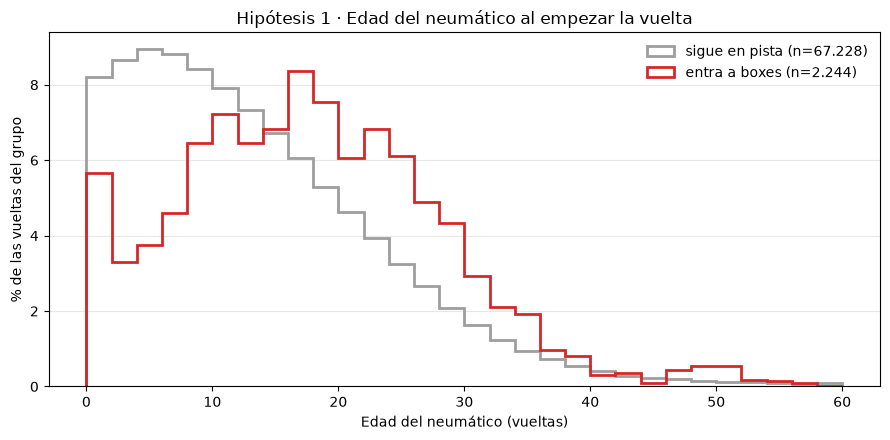

,count,25%,50%,75%
pit_stop,,,,
False,67228.0,5.0,11.0,19.0
True,2244.0,10.0,17.0,24.0


In [5]:
orden_vueltas = df.sort_values(CLAVE)
orden_vueltas["tyre_age_prev"] = orden_vueltas.groupby(["session_key", "driver_number"])["tyre_age"].shift(1)

fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.arange(0, 61, 2)
for valor, etiqueta, color in [(False, "sigue en pista", "#9e9e9e"), (True, "entra a boxes", "#d62728")]:
    edades = orden_vueltas.loc[orden_vueltas["pit_stop"] == valor, "tyre_age_prev"].dropna()
    ax.hist(edades, bins=bins, weights=np.full(len(edades), 100 / len(edades)),
            histtype="step", linewidth=2, color=color, label=f"{etiqueta} (n={len(edades):,})".replace(",", "."))
ax.set_title("Hipótesis 1 · Edad del neumático al empezar la vuelta")
ax.set_xlabel("Edad del neumático (vueltas)")
ax.set_ylabel("% de las vueltas del grupo")
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

orden_vueltas.groupby("pit_stop")["tyre_age_prev"].describe()[["count", "25%", "50%", "75%"]]

**Lectura.** El histograma muestra lo que el boxplot no dejaba ver. Las vueltas sin parada se concentran en gomas jóvenes y van bajando a medida que crece la edad. Las vueltas con parada tienen la masa corrida a la derecha: la mediana es **17 vueltas contra 11**, y el rango intercuartil es **10–24 contra 5–19**. El escalón de las paradas en 0–2 vueltas son las que no se planifican: daños, pinchaduras y cambios por lluvia. Igual hay mucha superposición, que es lo que daba la separación amarilla (0,409) de la Entrega 2: la edad sola no decide cuándo parar, porque depende del compuesto y del circuito.

### Obs. 10: hipótesis 4, los intermedios con safety car

En la Entrega 2 la hipótesis 4 («con safety car se monta un compuesto más blando») dio verde. La observación apunta a que buena parte de esas paradas son **intermedios**: el safety car aparece mucho en carreras con lluvia, y ahí la elección no es blando contra duro sino seco contra lluvia.

In [6]:
h4 = pits.merge(safety_car_paradas, on=CLAVE)
h4["safety car"] = h4["safety_car_active"].map({True: "con safety car", False: "sin safety car"})
h4["lluvia"] = np.where(h4["new_compound"].isin(["INTERMEDIATE", "WET"]), "monta lluvia", "monta seco")

tabla_h4 = pd.crosstab(h4["safety car"], h4["lluvia"], normalize="index").mul(100).round(1)
tabla_h4["paradas"] = h4["safety car"].value_counts()
tabla_h4["carreras"] = h4.groupby("safety car")["session_key"].nunique()
display(tabla_h4)

lluvia_sc = h4[h4["lluvia"] == "monta lluvia"]
print(f"De las {len(lluvia_sc)} paradas que montan intermedios/lluvia, "
      f"{lluvia_sc['safety_car_active'].mean():.0%} son con safety car, "
      f"y salen de {lluvia_sc['session_key'].nunique()} carreras.")
print(f"Paradas con safety car que montan lluvia: {(h4['safety_car_active'] & (h4['lluvia'] == 'monta lluvia')).sum()}"
      f" de {h4['safety_car_active'].sum()}")

lluvia,monta lluvia,monta seco,paradas,carreras
safety car,,,,
con safety car,27.9,72.1,269,20
sin safety car,7.4,92.6,2064,64


De las 227 paradas que montan intermedios/lluvia, 33% son con safety car, y salen de 6 carreras.
Paradas con safety car que montan lluvia: 75 de 269


**Lectura.** La observación se confirma. Con safety car, el **27,9 %** de las paradas monta intermedios o lluvia; sin safety car, el **7,4 %**. Son **75 de las 269** paradas con safety car, y todas las paradas de lluvia salen de apenas **6 carreras**. Buena parte de la «brecha verde» de la hipótesis 4 era **lluvia**, no safety car: cuando llueve hay más safety car y además se montan intermedios.

**Decisión.** `safety_car_active` sale, como pidieron. En la sección 8 la volvemos a agregar al modelo y no suma nada (−0,002 en el random forest y −0,015 en la logística). La lluvia ya entra por `rainfall`, `rain_so_far`, la humedad y el compuesto que lleva el pelotón.

# 2. El planteo

## 2.1 Qué predecimos

`new_compound`: el compuesto que el equipo monta en una parada. Es la segunda mitad de la pregunta del proyecto («si entra, ¿qué le pongo?») y es la que va a usar la aplicación de la Entrega 4: el usuario carga la situación de la parada y la app recomienda un compuesto.

**WET se une con INTERMEDIATE** en una clase `LLUVIA`. Con 7 paradas de WET en tres temporadas no hay nada que aprender, y para la decisión de estrategia la pregunta relevante es «seco o lluvia». Quedan cuatro clases: `SOFT`, `MEDIUM`, `HARD` y `LLUVIA`.

In [7]:
pits["objetivo"] = pits["new_compound"].replace({"INTERMEDIATE": "LLUVIA", "WET": "LLUVIA"})
distribucion = pd.DataFrame({"paradas": pits["objetivo"].value_counts(),
                             "%": pits["objetivo"].value_counts(normalize=True).mul(100).round(1)}).loc[ORDEN_CLASES]
distribucion

,paradas,%
objetivo,,
SOFT,343,14.7
MEDIUM,656,28.1
HARD,1107,47.4
LLUVIA,227,9.7


## 2.2 La métrica, declarada antes de elegir: **F1 macro**

Las clases están desparejas: HARD se lleva casi la mitad de las paradas y LLUVIA menos del 10 %. Con accuracy, un modelo que siempre dice HARD saca 47 % y parece razonable sin servir para nada.

**Qué error es más caro en nuestro problema.** Recomendar HARD cuando correspondía SOFT (o seco cuando llueve) es el error que hace perder la carrera, y está justo en las clases chicas. El **F1 macro** promedia el F1 de cada clase con el mismo peso, así que una clase chica mal predicha baja el número tanto como una grande. Por eso es la métrica que decide. Como apoyo reportamos accuracy y accuracy balanceada, pero **ninguna decisión se toma con ellas**.

## 2.3 La partición: imita el uso

Una fila es una parada, pero **las paradas no son independientes**: en una misma carrera paran los 20 pilotos con la misma lluvia, el mismo safety car y la misma degradación del asfalto. Si una parada de una carrera queda en entrenamiento y otra de la misma carrera en validación, el modelo «ve» la carrera y el número sale más alto que el real (lo medimos en la sección 6).

La aplicación se va a usar **en carreras que el modelo no vio, y posteriores a las de entrenamiento**. Por eso:

| Pieza | Cómo se arma | Por qué |
|---|---|---|
| **Test** | Toda la temporada **2025** (24 carreras), separada al principio y mirada **una sola vez** | Imita el uso real: entrenar con lo anterior y predecir lo que viene. También mide si el modelo aguanta el cambio de temporada |
| **Validación cruzada** | `StratifiedGroupKFold` de 5 pedazos sobre 2023–2024, con `groups = session_key` | Una carrera nunca queda de los dos lados; estratificado para que cada pedazo tenga las cuatro clases |

¿Por qué no `TimeSeriesSplit` adentro del entrenamiento? Con dos temporadas, partir por fecha deja pedazos de validación con una o dos carreras de lluvia, o ninguna, y el desvío se vuelve inmanejable. La dependencia temporal fuerte (el cambio de temporada) la cubre el test.

In [8]:
entrenamiento_mask = pits["season"] < 2025
pd.DataFrame({
    "paradas": pits.groupby(entrenamiento_mask.map({True: "entrenamiento 2023–2024", False: "test 2025"})).size(),
    "carreras": pits.groupby(entrenamiento_mask.map({True: "entrenamiento 2023–2024", False: "test 2025"}))["session_key"].nunique(),
}).join(pd.crosstab(entrenamiento_mask.map({True: "entrenamiento 2023–2024", False: "test 2025"}),
                    pits["objetivo"], normalize="index").mul(100).round(1)[ORDEN_CLASES])

,paradas,carreras,SOFT,MEDIUM,HARD,LLUVIA
season,,,,,,
entrenamiento 2023–2024,1518,40,13.8,25.2,51.7,9.3
test 2025,815,24,16.3,33.6,39.5,10.6


**Lectura.** Quedan **1.518 paradas de 40 carreras** para entrenar y validar, y **815 paradas de 24 carreras** para el test. La distribución cambia entre temporadas: en 2025 se monta menos HARD (39,5 % contra 51,7 %) y más MEDIUM (33,6 % contra 25,2 %). Eso es parte de lo que el test mide, porque en la Entrega 4 el modelo va a predecir temporadas que no vio. También explica por qué el piso «siempre HARD» rinde menos en el test que en la validación.

# 3. Las columnas: el estado de la carrera **en el momento de parar**

Cada columna tiene que existir **antes** de que el equipo decida qué goma poner. En la Entrega 2 encontramos que `current_compound` y `tyre_age` tienen fuga parcial en la vuelta del pit (en algunas filas ya muestran la goma nueva). Por eso todo lo que viene del CSV de vueltas se toma de la **vuelta anterior** del mismo piloto.

| Columna | Qué mide | De dónde sale | ¿Existe al decidir? |
|---|---|---|---|
| `compound_prev` | Compuesto con el que llega a boxes | `current_compound` de la vuelta anterior | Sí |
| `tyre_age_prev` | Edad de ese neumático | `tyre_age` de la vuelta anterior | Sí |
| `used_soft`, `used_medium`, `used_hard` | Si ya usó ese compuesto en la carrera | Vueltas anteriores del piloto | Sí. Captura la regla de usar dos compuestos de seco |
| `pit_stop_number` | 1.ª, 2.ª… parada | CSV de paradas | Sí |
| `laps_remaining`, `race_frac` | Vueltas que faltan y avance de carrera | Vueltas programadas del circuito (derivadas en el pipeline) | Sí |
| `field_soft_prev` … `field_wet_prev` | Qué compuesto lleva el pelotón | % de autos con cada compuesto en la vuelta anterior | Sí. El muro ve las gomas de los rivales |
| `rainfall`, `rain_so_far` | Si llueve ahora y si llovió antes en la carrera | Clima de la vuelta / vueltas anteriores | Sí |
| `track_temperature`, `air_temperature`, `humidity` | Clima | Último registro anterior a la vuelta | Sí |
| `position`, `gap_to_leader_raw` | Situación en carrera | Último dato anterior a la vuelta; el gap se convierte en el pipeline | Sí |
| `circuit_short_name`, `team_name` | Circuito y equipo | CSV de paradas | Sí (se prueban en la sección 8) |

**Vueltas programadas.** En la Entrega 2 marcamos que `session_max_lap_observed` se conoce recién al final de la carrera (en Interlagos 2024, acortada por lluvia, da 69 en lugar de 71). La reemplazamos por las **vueltas programadas del circuito**, que es un dato público antes de la carrera: el máximo observado en ese circuito en las tres temporadas.

**Lo que no entra, por fuga:** `new_stint_number` y `new_tyre_age_at_start` (describen la goma montada), `pit_duration`, `lane_duration` y `stop_duration` (se miden durante la parada), `driver_lap_count`, `laps_missing_until_session_max` y `possible_early_exit` (se conocen al final), y `tyre_age`/`current_compound` de la vuelta del pit.

In [9]:
vueltas = df.sort_values(CLAVE).copy()
por_piloto = vueltas.groupby(["session_key", "driver_number"])

# Estado del piloto al empezar la vuelta del pit: valores de la vuelta anterior.
vueltas["compound_prev"] = por_piloto["current_compound"].shift(1)
vueltas["tyre_age_prev"] = por_piloto["tyre_age"].shift(1)
vueltas["rain_so_far"] = por_piloto["rainfall"].transform(lambda s: s.shift(1).cummax())
for compuesto in ["SOFT", "MEDIUM", "HARD"]:
    usado = vueltas["current_compound"].eq(compuesto).astype(int)
    vueltas[f"used_{compuesto.lower()}"] = usado.groupby([vueltas["session_key"], vueltas["driver_number"]]) \
        .transform(lambda s: s.shift(1).cummax()).fillna(0)

# Estado del pelotón: % de autos con cada compuesto en la vuelta anterior.
peloton = pd.crosstab([vueltas["session_key"], vueltas["lap_number"]], vueltas["current_compound"], normalize="index")
peloton.columns = [str(c) for c in peloton.columns]
peloton = peloton.reset_index().assign(lap_number=lambda t: t["lap_number"] + 1)
peloton["field_wet_prev"] = peloton["INTERMEDIATE"] + peloton["WET"]
peloton = peloton.rename(columns={"SOFT": "field_soft_prev", "MEDIUM": "field_medium_prev", "HARD": "field_hard_prev"})
COLUMNAS_PELOTON = ["field_soft_prev", "field_medium_prev", "field_hard_prev", "field_wet_prev"]

# Vueltas programadas: dato público del circuito, no se usa el final observado de cada carrera.
vueltas_programadas = df.groupby("circuit_short_name")["session_max_lap_observed"].max().rename("scheduled_laps")

datos = (pits
         .merge(vueltas[CLAVE + ["compound_prev", "tyre_age_prev", "rain_so_far",
                                 "used_soft", "used_medium", "used_hard"]], on=CLAVE, how="left")
         .merge(peloton[["session_key", "lap_number"] + COLUMNAS_PELOTON], on=["session_key", "lap_number"], how="left")
         .merge(vueltas_programadas, left_on="circuit_short_name", right_index=True, how="left"))

# Parada en la vuelta 1: no hay vuelta anterior; el compuesto y la edad son los de largada (stint de entrada).
datos["compound_prev"] = datos["compound_prev"].fillna(datos["current_compound"])
datos["tyre_age_prev"] = datos["tyre_age_prev"].fillna(datos["tyre_age_at_start"])
datos["rain_so_far"] = datos["rain_so_far"].fillna(0)
datos = datos.merge(safety_car_paradas, on=CLAVE, how="left")  # sólo para el experimento de la sección 8

print("filas:", len(datos), "| claves duplicadas:", int(datos.duplicated(CLAVE).sum()))
datos[["compound_prev", "tyre_age_prev", "used_soft", "used_medium", "used_hard", "pit_stop_number",
       "scheduled_laps", "rain_so_far"] + COLUMNAS_PELOTON].isna().sum().rename("nulos").to_frame().T

filas: 2333 | claves duplicadas: 0


,compound_prev,tyre_age_prev,used_soft,used_medium,used_hard,pit_stop_number,scheduled_laps,rain_so_far,field_soft_prev,field_medium_prev,field_hard_prev,field_wet_prev
nulos,0,0,0,0,0,0,0,0,89,89,89,89


In [10]:
# Chequeo de fuga del compuesto de entrada: ¿coincide con la vuelta anterior o ya es el nuevo?
pd.Series({
    "compound_prev == current_compound del CSV de paradas (%)": round((datos["compound_prev"] == datos["current_compound"]).mean() * 100, 1),
    "compound_prev == new_compound (%)  (paradas que repiten compuesto)": round((datos["compound_prev"] == datos["new_compound"]).mean() * 100, 1),
    "current_compound == new_compound (%)": round((datos["current_compound"] == datos["new_compound"]).mean() * 100, 1),
}).to_frame("valor")

,valor
compound_prev == current_compound del CSV de paradas (%),98.5
compound_prev == new_compound (%) (paradas que repiten compuesto),30.1
current_compound == new_compound (%),30.3


**Lectura.** `compound_prev` coincide con el compuesto de entrada que corrigió el pipeline en el **98,5 %** de las paradas. El 1,5 % restante son las desalineaciones parada ↔ stint que vimos en la Entrega 2, y ahí nos quedamos con la vuelta anterior, que seguro es previa a la decisión. El **30 %** de coincidencia con `new_compound` no es fuga: son las paradas que repiten compuesto (HARD → HARD, por ejemplo).

# 4. El pipeline

Todo lo que se le hace a los datos está adentro del objeto que se entrena:

1. **`ColumnasDerivadas`**: calcula `laps_remaining`, `race_frac` y `n_dry_used` fila por fila (sin estadísticas del dataset).
2. **`GapALider`** (observaciones 1 y 2): convierte `gap_to_leader_raw` a segundos enteros, pone 0 al líder y reemplaza «+N LAP» por el máximo. **El máximo se aprende en `fit`**, o sea, sólo con los pedazos de entrenamiento de cada vuelta de la validación.
3. **Imputación** con la mediana del entrenamiento y **escalado** (para la regresión logística; a los árboles no les cambia nada pero los dejamos igual para comparar con las mismas columnas).
4. **One-hot** de las categóricas, con `handle_unknown="ignore"` para un circuito o equipo que no apareció en el entrenamiento.
5. El **modelo**.

In [11]:
class ColumnasDerivadas(BaseEstimator, TransformerMixin):
    """Columnas que se derivan fila por fila: no aprenden nada del dataset."""

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        X["laps_remaining"] = X["scheduled_laps"] - X["lap_number"]
        X["race_frac"] = X["lap_number"] / X["scheduled_laps"]
        X["n_dry_used"] = X["used_soft"] + X["used_medium"] + X["used_hard"]
        return X


class GapALider(BaseEstimator, TransformerMixin):
    """Obs. 1 y 2 de la Entrega 2: gap al líder en segundos enteros, líder = 0, doblados = máximo del entrenamiento."""

    def fit(self, X, y=None):
        self.maximo_ = float(pd.to_numeric(X["gap_to_leader_raw"], errors="coerce").max())
        return self

    def transform(self, X):
        segundos, _ = gap_a_segundos(X["gap_to_leader_raw"], X["position"], self.maximo_)
        return pd.DataFrame({"gap_to_leader_s": segundos.astype(float)}, index=X.index)

    def get_feature_names_out(self, input_features=None):
        return np.array(["gap_to_leader_s"])


NUMERICAS = ["laps_remaining", "race_frac", "tyre_age_prev", "pit_stop_number", "n_dry_used",
             "used_soft", "used_medium", "used_hard", "rain_so_far",
             "track_temperature", "air_temperature", "humidity", "position"] + COLUMNAS_PELOTON
CATEGORICAS = ["compound_prev", "rainfall"]
GAP = ["gap_to_leader_raw", "position"]


def armar_pipeline(modelo, numericas=NUMERICAS, categoricas=CATEGORICAS, usar_gap=True):
    numerico = Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())])
    partes = [("num", numerico, list(numericas)),
              ("cat", OneHotEncoder(handle_unknown="ignore"), list(categoricas))]
    if usar_gap:
        partes.append(("gap", Pipeline([("gap", GapALider()), ("imputar", SimpleImputer(strategy="median")),
                                        ("escalar", StandardScaler())]), GAP))
    return Pipeline([("derivadas", ColumnasDerivadas()),
                     ("preparar", ColumnTransformer(partes)),
                     ("modelo", modelo)])


train = datos[datos["season"] < 2025].reset_index(drop=True)
test = datos[datos["season"] == 2025].reset_index(drop=True)
X_train, y_train, grupos_train = train, train["objetivo"], train["session_key"]
X_test, y_test = test, test["objetivo"]

CV = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
METRICAS = {"f1_macro": "f1_macro", "accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy"}

armar_pipeline(LogisticRegression())

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('derivadas', ...), ('preparar', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default

In [12]:
# Cada pedazo de validación tiene carreras que no están en su entrenamiento, y las cuatro clases.
pd.DataFrame([{"pedazo": i + 1, "carreras val": grupos_train.iloc[va].nunique(),
               "paradas val": len(va),
               "carreras compartidas con entrenamiento": len(set(grupos_train.iloc[tr]) & set(grupos_train.iloc[va])),
               **y_train.iloc[va].value_counts().reindex(ORDEN_CLASES).to_dict()}
              for i, (tr, va) in enumerate(CV.split(X_train, y_train, grupos_train))]).set_index("pedazo")

,carreras val,paradas val,carreras compartidas con entrenamiento,SOFT,MEDIUM,HARD,LLUVIA
pedazo,,,,,,,
1,7,265,0,59.0,70.0,136.0,NaN
2,7,296,0,42.0,74.0,157.0,23.0
3,8,336,0,37.0,73.0,162.0,64.0
4,9,315,0,36.0,76.0,168.0,35.0
5,9,306,0,36.0,89.0,162.0,19.0


**Lectura.** Ningún pedazo comparte carreras con su entrenamiento: la partición por carrera funciona. **El pedazo 1 no tiene paradas de LLUVIA**, porque en 2023–2024 la lluvia está concentrada en **4 carreras** (Países Bajos 2023 con 64 paradas, São Paulo 2024 con 35, Gran Bretaña 2024 con 23 y Canadá 2024 con 19), y con 5 pedazos no alcanzan para todos. Esto explica buena parte del desvío entre pedazos que se ve más abajo: si el modelo predice LLUVIA donde no la hay, esa clase entra al F1 macro con 0.

# 5. La comparación

## 5.1 El piso

Dos modelos que **no miran ninguna columna**, con la misma validación que todo lo demás:
- `most_frequent`: siempre dice HARD.
- `stratified`: tira una moneda cargada con las proporciones de cada clase.

In [13]:
def evaluar(nombre, modelo, X=X_train, y=y_train, cv=CV, grupos=grupos_train, **kwargs):
    r = cross_validate(armar_pipeline(modelo, **kwargs), X, y, groups=grupos, cv=cv, scoring=METRICAS, n_jobs=-1)
    return {"modelo": nombre,
            "f1_macro": r["test_f1_macro"].mean(), "f1_macro_desvío": r["test_f1_macro"].std(),
            "accuracy": r["test_accuracy"].mean(), "balanced_acc": r["test_balanced_accuracy"].mean(),
            "_pedazos": r["test_f1_macro"]}


resultados = [
    evaluar("Piso: siempre HARD", DummyClassifier(strategy="most_frequent")),
    evaluar("Piso: al azar con proporciones", DummyClassifier(strategy="stratified", random_state=SEED)),
]
pd.DataFrame(resultados).drop(columns="_pedazos").set_index("modelo").round(3)

,f1_macro,f1_macro_desvío,accuracy,balanced_acc
modelo,,,,
Piso: siempre HARD,0.182,0.023,0.518,0.267
Piso: al azar con proporciones,0.242,0.021,0.345,0.256


**Lectura del piso.** Decir siempre HARD da **F1 macro 0,182 ± 0,023**, con una accuracy de 0,518 que parece aceptable y no sirve para nada: es exactamente el caso en que la accuracy engaña. La moneda cargada da 0,242. **Cualquier modelo tiene que superar 0,24 por más que su desvío para decir algo.**

## 5.2 El modelo simple primero, y tres familias más

Las mismas columnas, el mismo pipeline y los mismos 5 pedazos para todos. Los hiperparámetros iniciales son razonables pero no ajustados: el ajuste viene después, sólo para el elegido. Todos con `class_weight="balanced"`, salvo el boosting, que lo recibe igual (la decisión sobre los pesos se mide en la sección 7).

In [14]:
candidatos = {
    "Regresión logística": LogisticRegression(max_iter=5000, class_weight="balanced", random_state=SEED),
    "Árbol de decisión": DecisionTreeClassifier(max_depth=6, min_samples_leaf=10, class_weight="balanced", random_state=SEED),
    "Random forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=3, class_weight="balanced",
                                            random_state=SEED, n_jobs=-1),
    "Gradient boosting (HistGB)": HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
}
for nombre, modelo in candidatos.items():
    resultados.append(evaluar(nombre, modelo))

comparacion = pd.DataFrame(resultados).set_index("modelo")
comparacion.drop(columns="_pedazos").round(3)

,f1_macro,f1_macro_desvío,accuracy,balanced_acc
modelo,,,,
Piso: siempre HARD,0.182,0.023,0.518,0.267
Piso: al azar con proporciones,0.242,0.021,0.345,0.256
Regresión logística,0.444,0.101,0.578,0.488
Árbol de decisión,0.412,0.042,0.533,0.486
Random forest,0.558,0.137,0.634,0.580
Gradient boosting (HistGB),0.497,0.102,0.609,0.495


In [15]:
# Los cinco pedazos son los mismos para todos: comparamos la diferencia pedazo a pedazo contra la logística.
pedazos = pd.DataFrame({m: comparacion.loc[m, "_pedazos"] for m in comparacion.index}, index=[f"pedazo {i}" for i in range(1, 6)])
diferencias = pedazos.sub(pedazos["Regresión logística"], axis=0).drop(columns="Regresión logística")
display(pedazos.round(3))
pd.DataFrame({"diferencia media vs. logística": diferencias.mean(),
              "desvío de la diferencia": diferencias.std(ddof=0),
              "pedazos en que gana": (diferencias > 0).sum()}).round(3)

,Piso: siempre HARD,Piso: al azar con proporciones,Regresión logística,Árbol de decisión,Random forest,Gradient boosting (HistGB)
pedazo 1,0.226,0.209,0.478,0.473,0.674,0.636
pedazo 2,0.173,0.257,0.325,0.342,0.367,0.347
pedazo 3,0.163,0.239,0.381,0.411,0.425,0.420
pedazo 4,0.174,0.272,0.621,0.406,0.712,0.547
pedazo 5,0.173,0.232,0.415,0.428,0.613,0.535


,diferencia media vs. logística,desvío de la diferencia,pedazos en que gana
Piso: siempre HARD,-0.262,0.099,0
Piso: al azar con proporciones,-0.203,0.098,0
Árbol de decisión,-0.032,0.092,3
Random forest,0.114,0.070,5
Gradient boosting (HistGB),0.053,0.081,4


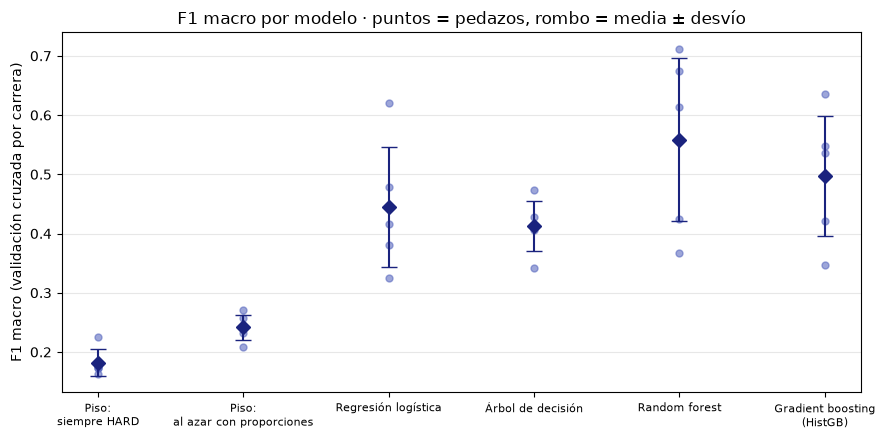

In [16]:
fig, ax = plt.subplots(figsize=(9, 4.5))
nombres = list(pedazos.columns)
for i, nombre in enumerate(nombres):
    ax.scatter(np.full(5, i), pedazos[nombre], color="#5c6bc0", alpha=0.6, s=25, zorder=3)
    ax.errorbar(i, pedazos[nombre].mean(), yerr=pedazos[nombre].std(ddof=0), fmt="D", color="#1a237e",
                capsize=6, markersize=7, zorder=4)
ax.set_xticks(range(len(nombres)))
ax.set_xticklabels([n.replace(": ", ":\n").replace(" (", "\n(") for n in nombres], fontsize=8)
ax.set_ylabel("F1 macro (validación cruzada por carrera)")
ax.set_title("F1 macro por modelo · puntos = pedazos, rombo = media ± desvío")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Lectura de la comparación.**

| Modelo | F1 macro (media ± desvío) | Diferencia pareada vs. logística | Pedazos en que gana |
|---|---|---|---|
| Piso: siempre HARD | 0,182 ± 0,023 | −0,262 | 0 de 5 |
| Regresión logística | **0,444 ± 0,101** | — | — |
| Árbol de decisión | 0,412 ± 0,042 | −0,032 ± 0,092 | 3 de 5 |
| Gradient boosting | 0,497 ± 0,102 | +0,053 ± 0,081 | 4 de 5 |
| **Random forest** | **0,558 ± 0,137** | **+0,114 ± 0,070** | **5 de 5** |

- La logística ya le gana al piso por mucho (0,444 contra 0,242): las columnas tienen señal.
- El desvío de cada modelo es grande porque **los pedazos son muy distintos entre sí**: el pedazo 2 es difícil para todos (0,33–0,37) y el 4 es fácil para todos. Como los cinco pedazos son los mismos para todos los modelos, la comparación justa es **la diferencia pedazo a pedazo**.
- El random forest le gana a la logística en **los 5 pedazos**, por **+0,114 en promedio con un desvío de 0,070**: le gana por más que el desvío. El boosting le gana por +0,053 ± 0,081 (dentro del ruido) y el árbol no le gana.

**Elegido: random forest.** Es el único complejo que le gana al simple por más que el desvío.

# 6. ¿Qué pasa si la validación se arma al azar?

Misma columnas, mismos modelos, pero con `StratifiedKFold` común: las paradas de una misma carrera quedan repartidas entre entrenamiento y validación.

In [17]:
CV_AZAR = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
azar = []
for nombre in ["Regresión logística", "Random forest"]:
    por_carrera = comparacion.loc[nombre]
    al_azar = evaluar(nombre, candidatos[nombre], cv=CV_AZAR, grupos=None)
    azar.append({"modelo": nombre, "F1 macro por carrera (honesto)": por_carrera["f1_macro"],
                 "F1 macro al azar": al_azar["f1_macro"],
                 "inflado": al_azar["f1_macro"] - por_carrera["f1_macro"]})
pd.DataFrame(azar).set_index("modelo").round(3)

,F1 macro por carrera (honesto),F1 macro al azar,inflado
modelo,,,
Regresión logística,0.444,0.642,0.198
Random forest,0.558,0.830,0.272


**Lectura.** Con la validación al azar, el F1 macro de la logística sube de **0,444 a 0,642** (+0,20) y el del random forest de **0,558 a 0,830** (+0,27). Ninguno de los dos mejoró: es **fuga entre paradas de la misma carrera**. Cuando en un safety car paran 15 autos y 12 quedan en entrenamiento, el modelo ya sabe qué se montó en esa carrera, con ese clima y esa vuelta. El random forest se infla más porque memoriza mejor esas combinaciones. Un 0,83 festejado habría sido el «número que da demasiado bien» del instructivo.

# 7. Clases desparejas: ¿`class_weight` o nada?

Medimos el elegido con y sin pesos balanceados, y miramos qué le pasa a cada clase. La métrica que decide sigue siendo el F1 macro.

In [18]:
def f1_por_clase(modelo):
    pred = cross_val_predict(armar_pipeline(modelo), X_train, y_train, groups=grupos_train, cv=CV, n_jobs=-1)
    por_clase = f1_score(y_train, pred, labels=ORDEN_CLASES, average=None)
    return {"F1 macro": f1_score(y_train, pred, average="macro"), "accuracy": accuracy_score(y_train, pred),
            **{f"F1 {c}": v for c, v in zip(ORDEN_CLASES, por_clase)}}


pesos = pd.DataFrame({
    "Random forest sin pesos": f1_por_clase(RandomForestClassifier(n_estimators=400, min_samples_leaf=3,
                                                                   random_state=SEED, n_jobs=-1)),
    "Random forest class_weight=balanced": f1_por_clase(candidatos["Random forest"]),
    "Logística sin pesos": f1_por_clase(LogisticRegression(max_iter=5000, random_state=SEED)),
    "Logística class_weight=balanced": f1_por_clase(candidatos["Regresión logística"]),
}).T
pesos.round(3)

,F1 macro,accuracy,F1 SOFT,F1 MEDIUM,F1 HARD,F1 LLUVIA
Random forest sin pesos,0.535,0.648,0.392,0.501,0.796,0.450
Random forest class_weight=balanced,0.543,0.631,0.422,0.525,0.780,0.446
Logística sin pesos,0.433,0.598,0.291,0.440,0.793,0.208
Logística class_weight=balanced,0.466,0.574,0.303,0.478,0.762,0.320


**Lectura.** Con `class_weight="balanced"` (F1 calculado sobre las predicciones de validación juntas), el random forest sube en F1 macro de **0,535 a 0,543**. SOFT pasa de 0,392 a 0,422 y MEDIUM de 0,501 a 0,525, a cambio de perder en HARD (0,796 → 0,780) y en accuracy (0,648 → 0,631). En la logística el efecto es mayor: 0,433 → 0,466, y LLUVIA pasa de 0,208 a 0,320.

**Decisión: `class_weight="balanced"`.** Cuesta 1,7 puntos de accuracy, pero la métrica que declaramos es el F1 macro y los pesos mejoran justo las clases chicas, que son los errores caros. No movimos el umbral: con cuatro clases no hay un único umbral, y los pesos ya hacen ese trabajo.

# 8. Las columnas que probamos y no sirvieron

Cada fila es el random forest con la misma validación, sacando (−) o agregando (+) un grupo de columnas respecto del conjunto base. Si la diferencia está dentro del desvío, la columna no suma.

In [19]:
RF_BASE = candidatos["Random forest"]
LOG_BASE = candidatos["Regresión logística"]
sin = lambda *quitar: [c for c in NUMERICAS if c not in quitar]

experimentos = {
    "base": {},
    "+ circuit_short_name (one-hot)": {"categoricas": CATEGORICAS + ["circuit_short_name"]},
    "+ team_name (one-hot)": {"categoricas": CATEGORICAS + ["team_name"]},
    "+ safety_car_active (obs. 3: eliminada)": {"categoricas": CATEGORICAS + ["safety_car_active"]},
    "+ virtual_safety_car_active": {"categoricas": CATEGORICAS + ["virtual_safety_car_active"]},
    "− gap_to_leader (obs. 1 y 2)": {"usar_gap": False},
    "− position": {"numericas": sin("position")},
    "− estado del pelotón (field_*_prev)": {"numericas": sin(*COLUMNAS_PELOTON)},
    "− compuestos ya usados (used_*, n_dry_used)": {"numericas": sin("used_soft", "used_medium", "used_hard", "n_dry_used")},
    "− clima (temperaturas y humedad)": {"numericas": sin("track_temperature", "air_temperature", "humidity")},
    "− rain_so_far": {"numericas": sin("rain_so_far")},
    "− tyre_age_prev": {"numericas": sin("tyre_age_prev")},
}

filas = []
for nombre, kwargs in experimentos.items():
    rf = evaluar(nombre, RF_BASE, **kwargs)
    lg = evaluar(nombre, LOG_BASE, **kwargs)
    filas.append({"experimento": nombre, "RF F1 macro": rf["f1_macro"], "RF desvío": rf["f1_macro_desvío"],
                  "Logística F1 macro": lg["f1_macro"]})
columnas = pd.DataFrame(filas).set_index("experimento")
columnas["RF diferencia vs. base"] = columnas["RF F1 macro"] - columnas.loc["base", "RF F1 macro"]
columnas["Logística diferencia vs. base"] = columnas["Logística F1 macro"] - columnas.loc["base", "Logística F1 macro"]
columnas.round(3)

,RF F1 macro,RF desvío,Logística F1 macro,RF diferencia vs. base,Logística diferencia vs. base
experimento,,,,,
base,0.558,0.137,0.444,0.000,0.000
+ circuit_short_name (one-hot),0.559,0.131,0.371,0.001,-0.073
+ team_name (one-hot),0.558,0.133,0.438,-0.000,-0.006
+ safety_car_active (obs. 3: eliminada),0.556,0.137,0.429,-0.002,-0.015
+ virtual_safety_car_active,0.557,0.132,0.445,-0.001,0.001
− gap_to_leader (obs. 1 y 2),0.554,0.135,0.447,-0.004,0.003
− position,0.561,0.138,0.442,0.003,-0.002
− estado del pelotón (field_*_prev),0.504,0.136,0.478,-0.054,0.034
"− compuestos ya usados (used_*, n_dry_used)",0.537,0.138,0.435,-0.021,-0.009


**Lectura.** El desvío del random forest es ~0,13, así que **sólo cuentan las diferencias grandes**.

**Las que no sirvieron (diferencia dentro del ruido, o negativa):**
- `circuit_short_name`: +0,001 en el RF y **−0,073 en la logística**. Con 24 circuitos y 40 carreras de entrenamiento, el one-hot memoriza «en este circuito llovió». Queda afuera, y además así el modelo sirve para un circuito nuevo.
- `team_name`: 0,000. Además cambia de nombre entre temporadas (AlphaTauri → RB → Racing Bulls).
- `safety_car_active` (obs. 3): −0,002. Confirma que se puede sacar.
- `virtual_safety_car_active`: −0,001.
- `gap_to_leader` (obs. 1 y 2): sacarlo cambia −0,004. Lo dejamos porque lo corregimos como se pidió, pero **no aporta**.
- `position`, `rain_so_far` y `tyre_age_prev`: sacarlas da +0,003, +0,005 y +0,011, todo dentro del desvío. Las dejamos: sacar columnas porque mejora 0,01 con un desvío de 0,14 también sería elegir por ruido.

**Las que sí sirven:** el **estado del pelotón** (sacarlo cuesta −0,054), el **clima** (−0,029) y los **compuestos ya usados** (−0,021, que es la regla de usar dos compuestos de seco).

Un dato curioso: a la logística, sacar el estado del pelotón **la mejora** (+0,034). Las cuatro proporciones suman 1 y están muy correlacionadas, y el modelo lineal no las aprovecha. El bosque sí.

# 9. Ajuste de hiperparámetros del elegido

Grilla sobre el random forest con la **misma** validación por carrera. Mostramos la tabla completa, no sólo el ganador.

In [20]:
grilla = GridSearchCV(
    armar_pipeline(RandomForestClassifier(n_estimators=400, class_weight="balanced", random_state=SEED, n_jobs=1)),
    param_grid={"modelo__max_depth": [4, 8, 12, None],
                "modelo__min_samples_leaf": [1, 3, 10, 25],
                "modelo__max_features": ["sqrt", 0.5]},
    scoring="f1_macro", cv=CV, n_jobs=-1, return_train_score=True)
grilla.fit(X_train, y_train, groups=grupos_train)

tabla_grilla = pd.DataFrame(grilla.cv_results_)[[
    "param_modelo__max_depth", "param_modelo__min_samples_leaf", "param_modelo__max_features",
    "mean_test_score", "std_test_score", "mean_train_score", "rank_test_score"]]
tabla_grilla.columns = ["max_depth", "min_samples_leaf", "max_features", "F1 val", "desvío val", "F1 entrenamiento", "puesto"]
tabla_grilla.sort_values("puesto").round(3).reset_index(drop=True)

,max_depth,min_samples_leaf,max_features,F1 val,desvío val,F1 entrenamiento,puesto
0,None,25,sqrt,0.577,0.048,0.770,1
1,12,25,sqrt,0.577,0.048,0.770,1
2,8,25,sqrt,0.575,0.049,0.773,3
3,None,3,0.5,0.565,0.145,0.920,4
4,12,3,0.5,0.563,0.143,0.918,5
5,4,25,sqrt,0.560,0.044,0.733,6
6,None,3,sqrt,0.558,0.137,0.914,7
7,12,3,sqrt,0.556,0.134,0.910,8
8,None,1,0.5,0.554,0.137,0.982,9
9,8,1,sqrt,0.553,0.131,0.907,10


Mejor combinación: {'modelo__max_depth': 12, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 25}
F1 macro en validación: 0.577 ± 0.048


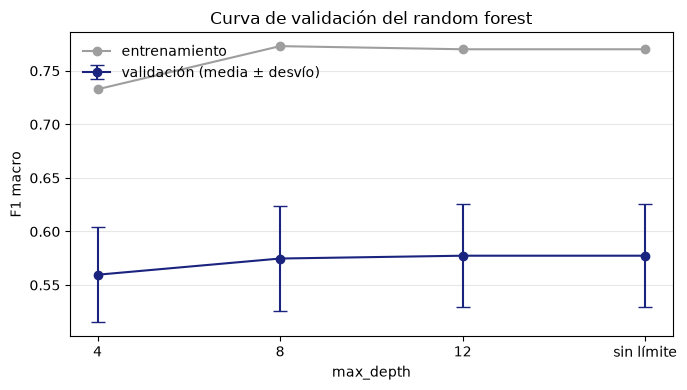

In [21]:
mejor = grilla.best_params_
print("Mejor combinación:", mejor)
print(f"F1 macro en validación: {grilla.best_score_:.3f} ± {grilla.cv_results_['std_test_score'][grilla.best_index_]:.3f}")

# Curva de validación de la profundidad, con el resto en su mejor valor.
curva = tabla_grilla[(tabla_grilla["min_samples_leaf"] == mejor["modelo__min_samples_leaf"])
                     & (tabla_grilla["max_features"] == mejor["modelo__max_features"])].copy()
curva["max_depth"] = curva["max_depth"].astype(object).where(curva["max_depth"].notna(), "sin límite").astype(str)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(curva["max_depth"], curva["F1 entrenamiento"], marker="o", color="#9e9e9e", label="entrenamiento")
ax.errorbar(curva["max_depth"], curva["F1 val"], yerr=curva["desvío val"], marker="o", color="#1a237e",
            capsize=5, label="validación (media ± desvío)")
ax.set_xlabel("max_depth")
ax.set_ylabel("F1 macro")
ax.set_title("Curva de validación del random forest")
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Lectura de la grilla (32 combinaciones).** La mejor es `max_depth=12`, `min_samples_leaf=25`, `max_features="sqrt"`, con **F1 macro 0,577 ± 0,048** (empata con `max_depth=None`, porque con hojas de 25 paradas el árbol casi nunca llega a profundidad 12).

- El hiperparámetro que más pesa es **`min_samples_leaf`**. Con hojas de 1 el F1 de entrenamiento es 0,98 y el de validación 0,55: sobreajuste. Con hojas de 25, el de entrenamiento baja a 0,77 y el de validación sube a 0,577.
- **El desvío cae de 0,137 a 0,048.** Con hojas grandes el bosque deja de memorizar las 4 carreras con lluvia, y los pedazos sin lluvia ya no lo castigan.
- `max_depth=4` queda corto (0,52–0,56) y `max_features=0.5` es peor en casi todas las combinaciones.
- La mejora respecto del bosque sin ajustar (0,558 → 0,577) está dentro del desvío. El ajuste vale sobre todo por la **estabilidad**.

# 10. El modelo final, medido **una vez** sobre el test

Todo lo que se eligió (modelo, columnas, pesos, hiperparámetros) se eligió con la validación cruzada sobre 2023–2024. Recién ahora se entrena con **todo** 2023–2024 y se mide **una sola vez** sobre 2025. El piso se mide sobre el mismo test, para que la comparación sea justa.

In [22]:
modelo_final = grilla.best_estimator_  # ya reentrenado por GridSearchCV con todo el entrenamiento
pred_test = modelo_final.predict(X_test)

piso_test = armar_pipeline(DummyClassifier(strategy="most_frequent")).fit(X_train, y_train).predict(X_test)
logistica_test = armar_pipeline(clone(LOG_BASE)).fit(X_train, y_train).predict(X_test)

final = pd.DataFrame({
    "Piso: siempre HARD": [f1_score(y_test, piso_test, average="macro"), accuracy_score(y_test, piso_test),
                           balanced_accuracy_score(y_test, piso_test)],
    "Regresión logística (referencia)": [f1_score(y_test, logistica_test, average="macro"),
                                         accuracy_score(y_test, logistica_test),
                                         balanced_accuracy_score(y_test, logistica_test)],
    "Random forest ajustado (elegido)": [f1_score(y_test, pred_test, average="macro"), accuracy_score(y_test, pred_test),
                                         balanced_accuracy_score(y_test, pred_test)],
}, index=["F1 macro", "accuracy", "accuracy balanceada"]).T
final["F1 macro en validación"] = [comparacion.loc["Piso: siempre HARD", "f1_macro"],
                                   comparacion.loc["Regresión logística", "f1_macro"], grilla.best_score_]
final.round(3)

,F1 macro,accuracy,accuracy balanceada,F1 macro en validación
Piso: siempre HARD,0.142,0.395,0.250,0.182
Regresión logística (referencia),0.616,0.622,0.652,0.444
Random forest ajustado (elegido),0.629,0.636,0.670,0.577


**Lectura del test (temporada 2025, mirado una sola vez).**

- **F1 macro 0,629**, contra **0,142** del piso en el mismo test: el modelo le gana al piso por **casi medio punto de F1 macro**. La accuracy balanceada es 0,670 (el azar con cuatro clases da 0,25).
- El test da **más alto que la validación** (0,577). No es fuga: 2025 tiene dos carreras de lluvia bien marcadas, que el modelo acierta (F1 de LLUVIA 0,69), y en la validación había un pedazo sin lluvia que bajaba el promedio. Está dentro de lo esperable para el desvío que medimos.
- **Lo que hay que decir con honestidad:** en el test, la logística da **0,616**, apenas 0,013 menos que el bosque. En la validación le ganaba por 0,114 en los 5 pedazos, y la elección se hizo ahí. No la cambiamos mirando el test, porque eso sería usarlo para elegir. Pero lo anotamos para la Entrega 4: si la app necesita explicar sus recomendaciones con coeficientes, la logística cuesta poco.

**¿Es mucho o poco?** Para recomendar un compuesto, acertar 64 de cada 100 paradas contra 40 del «siempre HARD», y reconocer 84 de cada 100 paradas de lluvia, sirve como **segunda opinión** para el muro. No alcanza para decidir solo, sobre todo en el final de carrera (sección 11).

# 11. Dónde se equivoca

In [23]:
print(classification_report(y_test, pred_test, labels=ORDEN_CLASES, digits=3))

              precision    recall  f1-score   support

        SOFT      0.439     0.647     0.523       133
      MEDIUM      0.670     0.518     0.584       274
        HARD      0.765     0.677     0.718       322
      LLUVIA      0.590     0.837     0.692        86

    accuracy                          0.636       815
   macro avg      0.616     0.670     0.629       815
weighted avg      0.661     0.636     0.639       815



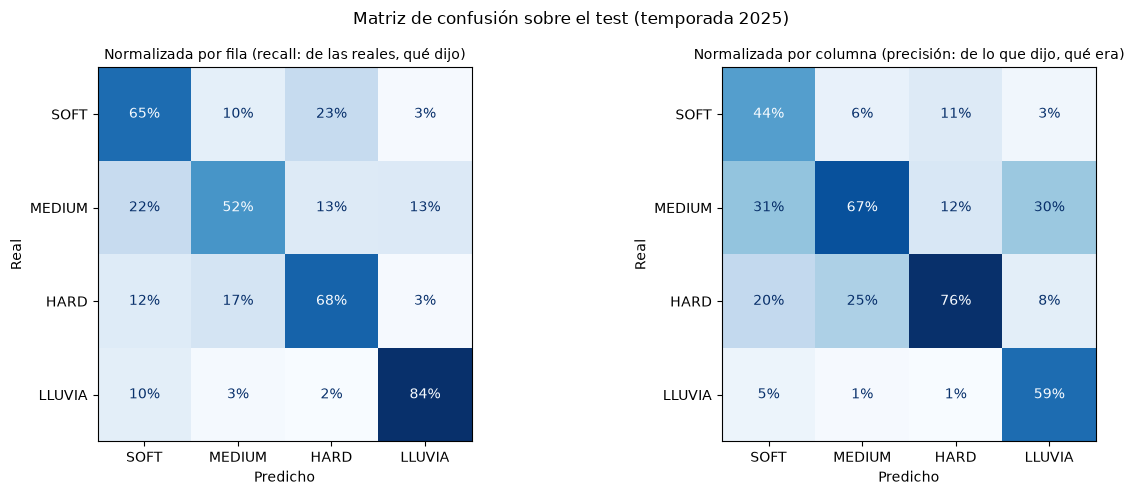

,pred SOFT,pred MEDIUM,pred HARD,pred LLUVIA
real SOFT,86,13,30,4
real MEDIUM,61,142,35,36
real HARD,40,54,218,10
real LLUVIA,9,3,2,72


In [24]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
for ax, normalizar, titulo in [(ejes[0], "true", "Normalizada por fila (recall: de las reales, qué dijo)"),
                               (ejes[1], "pred", "Normalizada por columna (precisión: de lo que dijo, qué era)")]:
    ConfusionMatrixDisplay.from_predictions(y_test, pred_test, labels=ORDEN_CLASES, normalize=normalizar,
                                            values_format=".0%", cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(titulo, fontsize=10)
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")
plt.suptitle("Matriz de confusión sobre el test (temporada 2025)")
plt.tight_layout()
plt.show()

pd.DataFrame(confusion_matrix(y_test, pred_test, labels=ORDEN_CLASES),
             index=[f"real {c}" for c in ORDEN_CLASES], columns=[f"pred {c}" for c in ORDEN_CLASES])

In [25]:
# ¿En qué tramo de la carrera se equivoca más? Acierto por vueltas restantes y por número de parada.
lectura = X_test.assign(real=y_test.values, predicho=pred_test,
                        acierto=(y_test.values == pred_test),
                        laps_remaining=X_test["scheduled_laps"] - X_test["lap_number"])
lectura["tramo"] = pd.cut(lectura["laps_remaining"], [-1, 10, 20, 35, 100],
                          labels=["≤10 vueltas", "11–20", "21–35", ">35"])
display(lectura.groupby("tramo", observed=True).agg(paradas=("acierto", "size"), acierto=("acierto", "mean"),
                                                    real_soft=("real", lambda s: (s == "SOFT").mean())).round(2))
display(lectura.groupby("compound_prev").agg(paradas=("acierto", "size"), acierto=("acierto", "mean")).round(2))

# Una confusión concreta: SOFT real que el modelo predijo como otra cosa.
soft_mal = lectura[(lectura["real"] == "SOFT") & (lectura["predicho"] != "SOFT")]
soft_mal[["meeting_name", "full_name", "lap_number", "laps_remaining", "compound_prev", "tyre_age_prev",
          "used_soft", "used_medium", "used_hard", "predicho"]].head(10)

,paradas,acierto,real_soft
tramo,,,
≤10 vueltas,70,0.31,0.31
11–20,137,0.55,0.31
21–35,274,0.64,0.17
>35,334,0.74,0.07


,paradas,acierto
compound_prev,,
HARD,210,0.56
INTERMEDIATE,94,0.67
MEDIUM,389,0.64
SOFT,122,0.72


,meeting_name,full_name,lap_number,laps_remaining,compound_prev,tyre_age_prev,used_soft,used_medium,used_hard,predicho
19,Japanese Grand Prix,Liam LAWSON,33,21,MEDIUM,31.0,0.0,1.0,0.0,HARD
20,Japanese Grand Prix,Carlos SAINZ,33,21,MEDIUM,31.0,0.0,1.0,0.0,HARD
43,Bahrain Grand Prix,Kimi ANTONELLI,27,30,MEDIUM,13.0,1.0,1.0,0.0,HARD
49,Bahrain Grand Prix,George RUSSELL,32,25,MEDIUM,17.0,1.0,1.0,0.0,HARD
54,Bahrain Grand Prix,Yuki TSUNODA,32,25,MEDIUM,19.0,1.0,1.0,0.0,HARD
56,Bahrain Grand Prix,Oliver BEARMAN,32,25,HARD,16.0,1.0,0.0,1.0,MEDIUM
57,Bahrain Grand Prix,Kimi ANTONELLI,32,25,SOFT,6.0,1.0,1.0,0.0,HARD
60,Bahrain Grand Prix,Liam LAWSON,32,25,HARD,16.0,0.0,1.0,1.0,MEDIUM
236,Qatar Grand Prix,Gabriel BORTOLETO,32,26,MEDIUM,23.0,0.0,1.0,0.0,HARD
280,São Paulo Grand Prix,Franco COLAPINTO,29,42,MEDIUM,27.0,0.0,1.0,0.0,HARD


In [26]:
# Por carrera: ¿hay carreras donde se cae?
por_carrera = lectura.groupby("meeting_name").agg(paradas=("acierto", "size"), acierto=("acierto", "mean"),
                                                  lluvia_real=("real", lambda s: (s == "LLUVIA").mean()))
display(por_carrera.sort_values("acierto").round(2).head(8))

# La carrera donde peor le va: qué tenía puesto el pelotón y qué predijo.
peor = por_carrera["acierto"].idxmin()
lectura[lectura["meeting_name"] == peor].groupby(["compound_prev", "real", "predicho"]).agg(
    paradas=("acierto", "size"), field_wet_prev=("field_wet_prev", "mean"), rainfall=("rainfall", "mean")).round(2)

,paradas,acierto,lluvia_real
meeting_name,,,
Belgian Grand Prix,26,0.00,0.00
British Grand Prix,35,0.37,0.51
Qatar Grand Prix,41,0.41,0.00
Monaco Grand Prix,40,0.42,0.00
Canadian Grand Prix,82,0.44,0.00
São Paulo Grand Prix,37,0.46,0.00
United States Grand Prix,21,0.52,0.00
Bahrain Grand Prix,42,0.64,0.00


paradas  field_wet_prev  rainfall
compound_prev real   predicho                                   
HARD          HARD   MEDIUM          3             0.0       0.0
MEDIUM        MEDIUM LLUVIA         19             0.0       0.0
                     SOFT            4             0.0       0.0

**Lectura de los errores.**

- **Por clase:** HARD es la mejor (F1 0,72). **LLUVIA tiene recall 0,84** pero precisión 0,59: cuando llueve casi nunca se le escapa, pero a veces ve lluvia donde no la hay. **SOFT tiene recall 0,65 y precisión 0,44**: lo predice de más, sobre todo en lugar de MEDIUM (61 MEDIUM reales predichos como SOFT).
- **Confusión concreta: MEDIUM ↔ SOFT ↔ HARD al elegir el segundo compuesto de seco.** En Japón, Lawson y Sainz paran en la vuelta 33 (faltan 21) con medios de 31 vueltas, sin haber usado otro compuesto. Montan SOFT y el modelo dice HARD. Las dos opciones cumplen la regla de los dos compuestos, y lo que decide es **cuántos juegos nuevos de cada compuesto le quedan al piloto**, un dato que OpenF1 no publica. Con 21 vueltas, un SOFT nuevo aguanta y es más rápido; si sólo quedara un SOFT usado, HARD era lo correcto.
- **Por tramo:** el acierto es **0,74 con más de 35 vueltas por delante y 0,31 en las últimas 10**. Al final de la carrera la parada suele ser oportunista (un safety car o una pinchadura) y se monta lo que haya disponible. El modelo no tiene esa información.
- **La carrera donde se cae: Bélgica 2025, 0 de 26.** La carrera largó con intermedios detrás del safety car y en las vueltas 11 a 13 todos pasaron a gomas de seco. Pero **OpenF1 registra el primer stint como MEDIUM en casi todos los pilotos** (en 19 de las 26 paradas `compound_prev` dice MEDIUM), cuando en realidad venían con intermedios. Con humedad del 81 % y el pelotón en «MEDIUM», el modelo dice LLUVIA y el real es MEDIUM. Es un error del dato de origen (capa bronce), no del modelo, y queda anotado para corregir en el pipeline.

# 12. En qué se apoya

**Importancia por permutación** sobre el test: se mezcla una columna por vez y se mide cuánto cae el F1 macro. Se hace sobre las columnas **de entrada** del pipeline (antes del one-hot), así cada columna original aparece una sola vez.

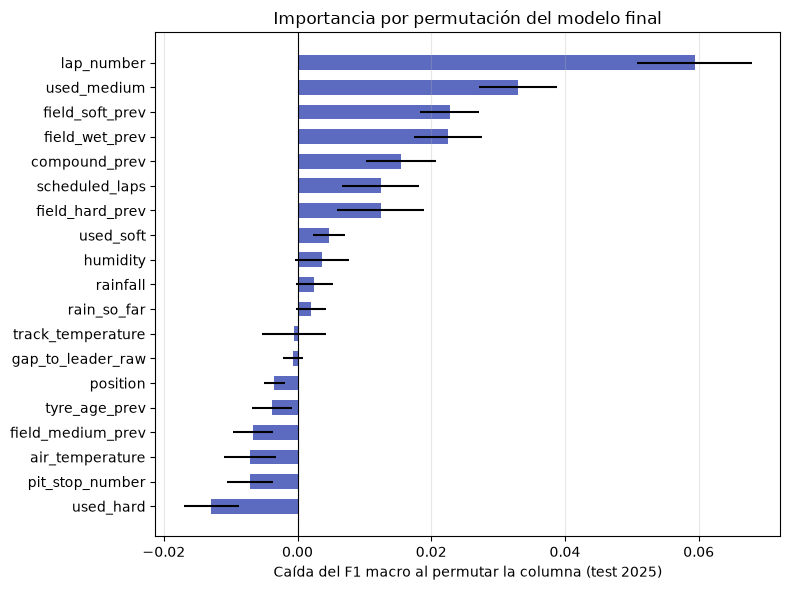

,caída media del F1 macro,desvío
lap_number,0.059,0.009
used_medium,0.033,0.006
field_soft_prev,0.023,0.004
field_wet_prev,0.022,0.005
compound_prev,0.015,0.005
scheduled_laps,0.012,0.006
field_hard_prev,0.012,0.006
used_soft,0.005,0.002
humidity,0.004,0.004
rainfall,0.003,0.003


In [27]:
COLUMNAS_ENTRADA = sorted(set(NUMERICAS) - {"laps_remaining", "race_frac", "n_dry_used"}
                          | set(CATEGORICAS) | set(GAP) | {"scheduled_laps", "lap_number"})
importancia = permutation_importance(modelo_final, X_test[COLUMNAS_ENTRADA], y_test, scoring="f1_macro",
                                     n_repeats=20, random_state=SEED, n_jobs=-1)
tabla_importancia = pd.DataFrame({"caída media del F1 macro": importancia.importances_mean,
                                  "desvío": importancia.importances_std}, index=COLUMNAS_ENTRADA) \
    .sort_values("caída media del F1 macro", ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
t = tabla_importancia.iloc[::-1]
ax.barh(t.index, t["caída media del F1 macro"], xerr=t["desvío"], color="#5c6bc0", height=0.6)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Caída del F1 macro al permutar la columna (test 2025)")
ax.set_title("Importancia por permutación del modelo final")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()
tabla_importancia.round(3)

In [28]:
# Chequeo de fuga de la columna que más pesa: ¿se conoce antes de la parada y tiene sentido de dominio?
top = tabla_importancia.index[0]
print("Columna que más pesa:", top)
print("lap_number y scheduled_laps juntas dan las vueltas que faltan (laps_remaining), que se conocen en todo momento.")
entrenamiento_lectura = X_train.assign(laps_remaining=X_train["scheduled_laps"] - X_train["lap_number"])
entrenamiento_lectura["tramo"] = pd.cut(entrenamiento_lectura["laps_remaining"], [-1, 10, 20, 35, 100],
                                        labels=["≤10 vueltas", "11–20", "21–35", ">35"])
pd.crosstab(entrenamiento_lectura["tramo"], y_train, normalize="index").mul(100).round(1)[ORDEN_CLASES]     .assign(paradas=entrenamiento_lectura["tramo"].value_counts())

Columna que más pesa: lap_number
lap_number y scheduled_laps juntas dan las vueltas que faltan (laps_remaining), que se conocen en todo momento.


objetivo,SOFT,MEDIUM,HARD,LLUVIA,paradas
tramo,,,,,
≤10 vueltas,48.5,5.9,0.0,45.6,68
11–20,30.2,29.7,30.7,9.4,192
21–35,9.9,26.5,59.1,4.5,506
>35,9.2,24.9,56.8,9.2,752


**Lectura de la importancia.**

- **La que más pesa es `lap_number`** (permutarla baja el F1 macro 0,059). Junto con `scheduled_laps` da las vueltas que faltan. **¿Es fuga?** No: la vuelta en curso y las vueltas programadas se conocen en todo momento y no contienen la respuesta. La tabla de dominio lo confirma: con 10 vueltas o menos por delante se monta SOFT en el **48,5 %** de las paradas; con más de 35, en el **9,2 %**. Cerca del final no hace falta durar.
- **Pero hay una trampa, y la encontramos acá:** con 10 vueltas o menos, el **45,6 %** de las paradas de entrenamiento son de LLUVIA, y casi todas son de **una sola carrera** (Países Bajos 2023, con lluvia en el final). Una parte de la importancia de `lap_number` es entonces «en el final llueve», que es un patrón de una carrera y no de la F1. No es fuga, porque el dato existe al decidir, pero sí es un sobreajuste a pocas carreras.
- Después vienen **`used_medium`** (0,033: si ya usó medios, la regla de los dos compuestos empuja a otro), el **pelotón en SOFT y en lluvia** (0,023 y 0,022: los equipos copian lo que funciona) y **`compound_prev`** (0,015).
- **Columnas con importancia negativa:** `used_hard` (−0,013), `pit_stop_number`, `air_temperature`, `field_medium_prev`, `tyre_age_prev` y `position`. Permutarlas **mejora** el test, o sea que son ruido. No las sacamos ahora, porque eso sería elegir columnas mirando el test. Quedan como primera tarea de la Entrega 4, y se van a medir otra vez con validación cruzada.

# 13. Cierre

## Resumen

| | |
|---|---|
| **Qué predecimos** | `new_compound` (SOFT, MEDIUM, HARD o LLUVIA) en cada parada |
| **Métrica** | F1 macro: los errores caros (SOFT y LLUVIA) están en las clases chicas |
| **Partición** | Test = temporada 2025 completa; validación = `StratifiedGroupKFold` por carrera sobre 2023–2024 |
| **Piso** | 0,182 en validación, 0,142 en el test (siempre HARD) |
| **Simple** | Regresión logística: 0,444 ± 0,101 en validación |
| **Elegido** | Random forest (`max_depth=12`, `min_samples_leaf=25`, `max_features="sqrt"`, `class_weight="balanced"`): 0,577 ± 0,048 en validación |
| **Test, una vez** | **F1 macro 0,629**, accuracy 0,636, accuracy balanceada 0,670 |

## Lo que probamos y no anduvo

1. **Circuito como columna:** a la logística le cuesta 0,073 de F1 macro y al bosque no le suma. Memoriza en qué circuito llovió.
2. **Equipo, safety car, VSC, gap al líder y posición:** dentro del ruido. El safety car, que en la Entrega 2 parecía verde, era en buena parte lluvia (obs. 10).
3. **Validar al azar:** daba 0,83, y era fuga entre paradas de la misma carrera.
4. **El árbol solo y el boosting:** no le ganaron a la logística por más que el desvío.
5. **Hojas chicas en el bosque:** F1 de 0,98 en entrenamiento, sobreajuste puro.
6. **Lo que no apareció:** esperábamos que la **edad del neumático** pesara mucho para elegir el compuesto, y su importancia es nula, incluso negativa. La edad sirve para decidir *cuándo* parar (hipótesis 1), no *qué* poner.

## Para la Entrega 4

- Volver a medir con validación cruzada si se pueden sacar las columnas con importancia negativa.
- Corregir en el pipeline el primer stint de Bélgica 2025 (y buscar otros casos parecidos con largada en mojado).
- Para la app: el usuario carga compuesto actual, compuestos ya usados, vuelta, vueltas programadas, clima y qué lleva el pelotón, y el modelo devuelve las probabilidades de cada compuesto, no sólo la clase ganadora.

## Las seis preguntas del instructivo, con nuestra respuesta corta

1. **¿Por qué F1 macro?** Porque el error caro es no ver SOFT o LLUVIA, que son el 15 % y el 10 % de las paradas. La accuracy premia decir HARD siempre (0,518 sin mirar nada).
2. **¿Cuánto le gana al piso?** En el test, 0,629 contra 0,142. Sirve como recomendación, no como decisión automática.
3. **¿Por qué los pedazos por carrera?** Porque las paradas de una carrera comparten lluvia, safety car y degradación. Al azar, el número sube a 0,83 y es fuga.
4. **¿Por qué random forest y no uno más complejo?** Le gana a la logística en los 5 pedazos por +0,114 ± 0,070. El boosting, que es más complejo, no le gana a la logística por más que el desvío.
5. **Una confusión concreta:** el segundo compuesto de seco (SOFT o HARD) cuando faltan unas 20 vueltas. Depende de los juegos de neumáticos que le quedan a cada piloto, un dato que no tenemos. Y Bélgica 2025, que es un error del dato de origen.
6. **La columna que más pesa:** `lap_number` (vueltas que faltan). No es fuga porque se conoce siempre, pero parte de su peso viene de una sola carrera con lluvia en el final. Lo verificamos con la tabla por tramo.